Your immune system must recognise an almost unlimited variety of invaders (viruses, bacteria, fungi, parasites, and your own cells when they turn cancerous) while leaving your healthy tissues alone. It does this with two layers: a fast, generic **innate** system, and a slow but extraordinarily specific **adaptive** system that learns and remembers. Over the last 15 years, learning to release the brakes on the adaptive system against tumours (**immunotherapy**) has changed cancer treatment more than anything since chemotherapy. Antibodies are also the fastest-growing class of drugs.

:::eli5
Your body has security guards. The first team (**innate immunity**) patrols everywhere and attacks anything that looks generally suspicious, like bacterial coats. The second team (**adaptive immunity**) is a giant library of specialists: millions of different cells, each able to recognise just one shape. When an invader appears, the few specialists that recognise it are woken up and copy themselves into an army. Afterwards some stay on as veterans (**memory**) so the next attack is crushed before you notice. A **vaccine** is a training exercise: it shows the specialists a harmless picture of the enemy.
:::

## The cast

| Cell | Team | Job |
|---|---|---|
| **Neutrophils** | innate | most numerous white cell; eat and kill bacteria; first to arrive |
| **Macrophages** | innate | eat microbes and debris; raise the alarm with signalling proteins (**cytokines**) |
| **Dendritic cells** | link | capture invaders' proteins and *show* them to T cells in lymph nodes |
| **NK cells** | innate | kill cells that are stressed or have lost their identity markers (common in tumours and virus-infected cells) |
| **B cells** | adaptive | make **antibodies**; mature into antibody factories (**plasma cells**) |
| **CD4⁺ helper T cells** | adaptive | coordinate: help B cells and killer T cells; the cells HIV destroys |
| **CD8⁺ killer (cytotoxic) T cells** | adaptive | kill infected and cancerous cells |
| **Regulatory T cells** | adaptive | calm the response; prevent autoimmunity |

Innate cells recognise broad molecular patterns that mark microbes as foreign (bacterial cell-wall molecules, double-stranded RNA) using receptors such as the **Toll-like receptors**. Adaptive cells each carry a unique receptor that recognises one specific molecular shape, called an **antigen**.

## Antibodies

An **antibody** is a Y-shaped protein made of two identical **heavy chains** and two identical **light chains** (chapter P5's quaternary structure). The tips of the Y are **variable**: six loops there, the **complementarity-determining regions** (CDRs), form a binding surface unique to each B-cell lineage. The stem is **constant** and tells the rest of the immune system what to do with whatever the antibody grabs.

Antibodies protect by **neutralising** (blocking a virus from entering cells), **tagging** invaders for destruction by phagocytes and complement proteins, and recruiting NK cells to kill antibody-coated cells. Because they can be designed to grab almost any target, **monoclonal antibodies** are now a huge drug class: trastuzumab (HER2, breast cancer), rituximab (CD20, lymphoma), pembrolizumab (PD-1, many cancers), adalimumab (TNF, arthritis).

## Where does the diversity come from?

You have about 20,000 genes, yet you can make billions of different antibodies. The trick is **V(D)J recombination**. Each developing B cell builds its antibody genes by cutting and pasting: it picks one **V**, one **D** and one **J** gene segment from libraries of each and joins them, and the joins themselves are sloppy, with bases randomly added or removed. T-cell receptors are built the same way.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(10)

# approximate numbers of functional human gene segments
heavy = 40 * 23 * 6                    # V x D x J
kappa, lam = 40 * 5, 30 * 4
light = kappa + lam
combinatorial = heavy * light
junctional = 1e7                       # rough extra factor from random nucleotides added and removed at the joins
print(f"heavy chains from V(D)J choice: {heavy:,}")
print(f"light chains: {light}")
print(f"heavy x light pairings: {combinatorial:,.0f}")
print(f"including junctional diversity: about {combinatorial * junctional:.0e}")
R["comb"] = f"{combinatorial / 1e6:.1f} million"; R["total"] = f"10^{np.log10(combinatorial * junctional):.0f}"

heavy chains from V(D)J choice: 5,520
light chains: 320
heavy x light pairings: 1,766,400
including junctional diversity: about 2e+13


Choosing segments alone gives about 1.8 million combinations; the random additions and deletions at the joins raise the potential to about 10^13. That is far more than the roughly 10¹¹ B cells you have, so at any moment you carry only a sample of the possible repertoire, but a sample diverse enough that a few cells recognise almost anything. Cells whose receptors bind your *own* molecules are mostly eliminated during development (**tolerance**); when that fails, the result is **autoimmune disease**.

:::data
**Immune repertoire sequencing** (AIRR-seq) reads millions of antibody or T-cell receptor sequences from a blood sample. Expanded clones reveal what the immune system is fighting, and machine learning on repertoires is an active research area for diagnostics and antibody discovery.
:::

## Clonal selection: from a few cells to an army

When an antigen arrives, the rare B and T cells whose receptors bind it are activated and divide rapidly: **clonal expansion**. One cell dividing every 8 hours for a week becomes about 2 million. Then most die off, leaving **memory cells** that respond faster and to smaller amounts of antigen next time. Here is the model behind the playground's first tab, run for a primary infection, a repeat infection, and a vaccine followed by infection:

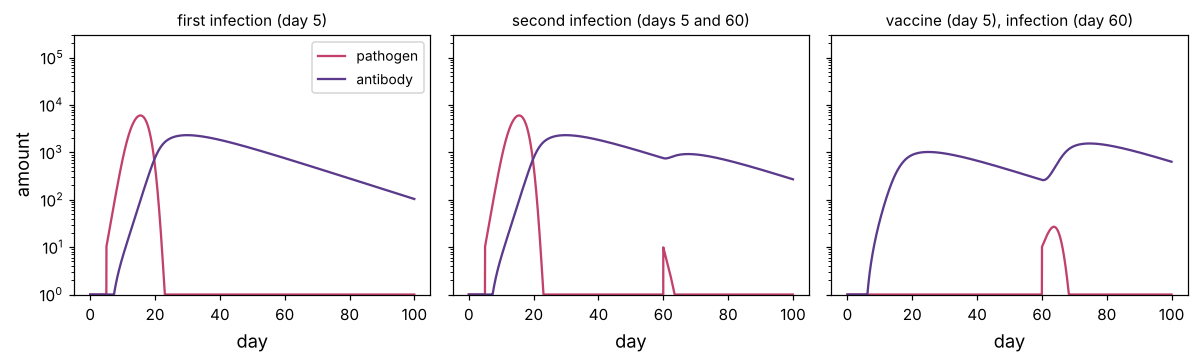

first infection (day 5)                peak pathogen before day 60:      6009   after day 60:         0
second infection (days 5 and 60)       peak pathogen before day 60:      6009   after day 60:        10
vaccine (day 5), infection (day 60)    peak pathogen before day 60:         0   after day 60:        27


In [2]:
def immune(events, T=100, dt=0.02):
    """Pathogen P, activated B cells B, antibody A, innate response I, memory M, vaccine antigen V."""
    P = B = A = I = V = 0.0; M = 1.0
    out = []
    ev = {round(t / dt): k for t, k in events}
    for step in range(int(T / dt)):
        k = ev.get(step)
        if k == "infect": P += 10
        if k == "vaccine": V += 3e4
        g = P + V
        sN, sM = g / (g + 1e3), g / (g + 20)                  # memory cells need far less antigen
        dP = 0.9 * P * (1 - P / 1e6) - 0.4 * P * I - 0.002 * A * P
        dB = 0.6 * sN * (B + 1) + 1.0 * sM * M - 0.15 * B
        dA = 0.8 * B - 0.05 * A
        dI = 0.8 * P / (P + 1e3) - 0.3 * I
        dM = 0.05 * B if M < 1000 else 0
        dV = -0.3 * V - 0.002 * A * V
        P = max(P + dt * dP, 0); P = 0 if P < 1 else P
        B, A, I, M, V = B + dt * dB, A + dt * dA, I + dt * dI, M + dt * dM, max(V + dt * dV, 0)
        out.append((step * dt, P, A))
    return np.array(out)

scenarios = {"first infection (day 5)": [(5, "infect")],
             "second infection (days 5 and 60)": [(5, "infect"), (60, "infect")],
             "vaccine (day 5), infection (day 60)": [(5, "vaccine"), (60, "infect")]}
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
peaks = {}
for ax, (name, ev) in zip(axs, scenarios.items()):
    d = immune(ev)
    ax.semilogy(d[:, 0], np.maximum(d[:, 1], 1), color="#c2416b", label="pathogen")
    ax.semilogy(d[:, 0], np.maximum(d[:, 2], 1), color="#5b3a8c", label="antibody")
    ax.set_title(name, fontsize=10); ax.set_xlabel("day"); ax.set_ylim(1, 3e5)
    late = d[d[:, 0] >= 60, 1]
    peaks[name] = (d[d[:, 0] < 60, 1].max(), late.max() if len(late) else 0)
axs[0].set_ylabel("amount"); axs[0].legend(fontsize=9)
save_fig("immune_memory"); plt.show()
for k, (p1, p2) in peaks.items():
    print(f"{k:38s} peak pathogen before day 60: {p1:9.0f}   after day 60: {p2:9.0f}")
R["peak1"] = f"{peaks['first infection (day 5)'][0]:,.0f}"
R["peak2"] = f"{peaks['second infection (days 5 and 60)'][1]:,.0f}"
R["peakv"] = f"{peaks['vaccine (day 5), infection (day 60)'][1]:,.0f}"

![Figure P10-1. A simple model of clonal selection. In a first infection, the pathogen grows for about a week before antibody catches up. A second infection is stopped almost at once by memory cells. A vaccine creates the same memory without the first illness.](images/immune_memory.png)

The first infection peaks at about 6,009 pathogen units. The same dose two months later peaks at only 10, and after vaccination at 27. The model is a cartoon (real responses involve dozens of cell types), but it captures the logic of immunological memory and of every vaccine.

### Affinity maturation: evolution inside a lymph node

Antibodies improve during a response. Activated B cells move into **germinal centres** in lymph nodes, where they mutate their antibody genes at about a million times the normal rate (**somatic hypermutation**) and then compete for antigen: cells whose mutated antibodies bind better get more help from T cells and survive. This is chapter P8's mutation-plus-selection loop, run over days instead of millennia.

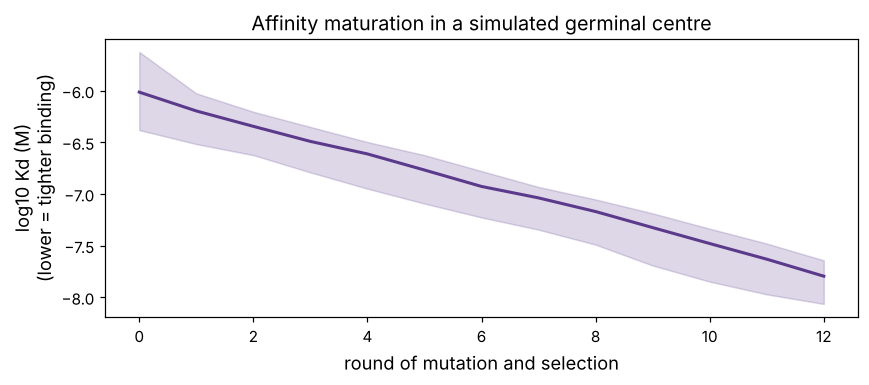

median Kd from 9.7e-07 M to 1.6e-08 M: 61-fold tighter


In [3]:
def germinal_centre(rounds=12, n=2000, keep=0.5):
    log_kd = rng.normal(-6, 0.3, n)                        # starting affinities around 1 µM (log10 M)
    history = [log_kd.copy()]
    for _ in range(rounds):
        effect = rng.normal(0.1, 0.25, n)                   # most mutations hurt binding a little; a few help
        mutated = log_kd + effect * (rng.random(n) < 0.3)   # about a third of the cells pick up a mutation per round
        survivors = np.sort(mutated)[: int(keep * n)]       # the best binders (lowest Kd) win the competition
        log_kd = rng.choice(survivors, n)                   # survivors divide to refill the germinal centre
        history.append(log_kd.copy())
    return np.array(history)

hist = germinal_centre()
fig, ax = plt.subplots(figsize=(8, 3.6))
med = np.median(hist, axis=1)
ax.fill_between(range(len(hist)), np.percentile(hist, 10, 1), np.percentile(hist, 90, 1), color="#5b3a8c", alpha=0.2)
ax.plot(med, color="#5b3a8c", lw=2)
ax.set_xlabel("round of mutation and selection"); ax.set_ylabel("log10 Kd (M)\n(lower = tighter binding)")
ax.set_title("Affinity maturation in a simulated germinal centre")
save_fig("affinity"); plt.show()
fold = 10 ** (med[0] - med[-1])
R["fold"] = f"{fold:,.0f}"
print(f"median Kd from {10 ** med[0]:.1e} M to {10 ** med[-1]:.1e} M: {fold:,.0f}-fold tighter")

![Figure P10-2. Median and 10–90% range of antibody affinity over rounds of hypermutation and selection. Even though most mutations make binding slightly worse, selection drives affinity up steadily.](images/affinity.png)

In 12 rounds the median antibody binds about 61 times more tightly, even though the average mutation is harmful. Real responses go from micromolar to nanomolar or better in a few weeks. Antibody engineers copy this process in the lab (with phage or yeast display), and machine-learning models now propose mutations directly (chapter 10).

## T cells and MHC: showing the inside of a cell

Antibodies see molecules floating outside cells. But a virus hiding inside a cell, or a mutant protein in a cancer cell, is invisible to them. T cells solve this. Every cell constantly chops a sample of its own proteins into short **peptides** (8–11 amino acids) and displays them on its surface in the groove of **MHC class I** molecules (in humans called **HLA**). A killer T cell whose receptor recognises a foreign peptide in an MHC groove kills that cell. In effect, every cell is continuously showing a summary of its proteome to passing T cells.

HLA genes are the most variable genes in the human genome (thousands of alleles), and each HLA variant binds peptides with particular **anchor residues** at particular positions. The most common in Europe, **HLA-A\*02:01**, prefers leucine or methionine at position 2 and valine, leucine or isoleucine at the last position.

### Cancer neoantigens

A somatic mutation in a tumour changes a protein, so peptides containing the mutation are new to the immune system: **neoantigens**. If one of them fits the patient's HLA, T cells can recognise the tumour. Predicting which mutant peptides will be presented is a central task in computational immunology (tools such as NetMHCpan are neural networks trained on hundreds of thousands of measured peptide–HLA pairs). Here is a toy version with a simple anchor-based score for HLA-A\*02:01, applied to the KRAS G12V mutation (glycine to valine at position 12), which occurs in many pancreatic, colorectal and lung cancers.

In [4]:
from Bio import SeqIO
kras = str(SeqIO.read("datasets/KRAS_P01116.fasta", "fasta").seq)
pos = 12                                                 # 1-based position of the mutated residue
assert kras[pos - 1] == "G"
mutant = kras[: pos - 1] + "V" + kras[pos:]

P2 = {"L": 3, "M": 3, "I": 1.5, "V": 1, "A": 0.5, "T": 0.5}     # position-2 anchor preferences (simplified)
PC = {"V": 3, "L": 3, "I": 2.5, "A": 1, "M": 1}                  # C-terminal anchor preferences
BAD = set("DEKRHP")                                              # charged or proline: disfavoured in the middle
def a2_score(pep):
    middle = sum(-0.5 for a in pep[2:-1] if a in BAD)
    return P2.get(pep[1], -1) + PC.get(pep[-1], -1) + middle

rows = []
for L in (9, 10):
    for start in range(pos - L, pos):                    # every window that covers the mutation
        if start < 0:
            continue
        mut_pep, wt_pep = mutant[start:start + L], kras[start:start + L]
        rows.append((a2_score(mut_pep), mut_pep, wt_pep, start + 1))
rows.sort(reverse=True)
print("score  mutant peptide   normal peptide   starts at")
for sc, m, w, st in rows[:6]:
    print(f"{sc:5.1f}  {m:15s}  {w:15s}  {st}")
R["top_pep"] = rows[0][1]

score  mutant peptide   normal peptide   starts at
  6.0  KLVVVGAVGV       KLVVVGAGGV       5
  4.0  LVVVGAVGV        LVVVGAGGV        6
  3.5  AVGVGKSAL        AGGVGKSAL        11
  3.0  GAVGVGKSAL       GAGGVGKSAL       10
  2.0  YKLVVVGAV        YKLVVVGAG        4
  2.0  KLVVVGAVG        KLVVVGAGG        5


The top candidate, `KLVVVGAVGV` (KRAS residues 5–14 carrying G12V), has leucine at position 2 and valine at the end, a textbook HLA-A\*02:01 shape. It has in fact been shown experimentally to be presented by HLA-A\*02:01 and recognised by T cells, and T-cell receptors against KRAS mutant peptides are being tested as cancer therapies.

But look at its normal counterpart: it has the same anchors and scores exactly the same. The mutation sits in the middle of the peptide, away from the anchors, so it doesn't decide *whether* the peptide is displayed; it changes *what the T-cell receptor sees* in the displayed peptide. A useful neoantigen therefore needs two things: the mutant peptide must be presented, and it must look different enough from the normal one that T cells can tell them apart. Real predictors use the full binding matrix for each HLA allele plus models of how proteins are chopped and transported, and predicting which presented peptides actually trigger T cells is still an open problem.

## How tumours escape, and immunotherapy

The immune system does kill many nascent tumours, so the cancers that grow are the ones that escaped (chapter P8's selection again). Escape routes include losing HLA expression, hiding behind immunosuppressive cells, and exploiting **immune checkpoints**: brakes such as **PD-1** and **CTLA-4** on T cells that normally prevent autoimmunity. Many tumours display **PD-L1**, which engages PD-1 and switches off the T cells attacking them.

| Approach | How it works | Examples |
|---|---|---|
| **Checkpoint inhibitors** | antibodies that block PD-1, PD-L1 or CTLA-4, releasing the brakes | pembrolizumab, nivolumab, ipilimumab (Nobel Prize 2018 for the discovery) |
| **CAR-T cells** | a patient's T cells engineered with a synthetic receptor (antibody tip + T-cell signalling) against a tumour protein | CD19 CAR-T for leukaemia and lymphoma |
| **Bispecific antibodies** | one arm grabs a T cell, the other a tumour cell | blinatumomab |
| **Cancer vaccines** | train T cells on the patient's own neoantigens | personalised mRNA neoantigen vaccines in trials |

Checkpoint inhibitors work best in tumours with many mutations (high **tumour mutational burden**: melanoma, lung cancer in smokers, tumours with broken DNA mismatch repair), because more mutations mean more neoantigens for the released T cells to see. Predicting who will respond is a major open problem for computational biology.

## Herd immunity

Vaccines protect individuals and also populations. In the classic **SIR** epidemic model, people are Susceptible, Infected or Recovered. Each case infects $R_0$ others in a fully susceptible population; if a fraction $s$ is still susceptible, the effective number is $R_0 s$. The epidemic grows only while $R_0 s > 1$.

:::math
**Herd immunity threshold:** the epidemic cannot take off once the immune fraction exceeds $1 - 1/R_0$.

**Final size:** without intervention, the fraction $z$ eventually infected satisfies $z = 1 - e^{-R_0 z}$. If a fraction $v$ is immune beforehand, the infected fraction of the remaining population satisfies $z = 1 - e^{-R_0 (1 - v) z}$.
:::

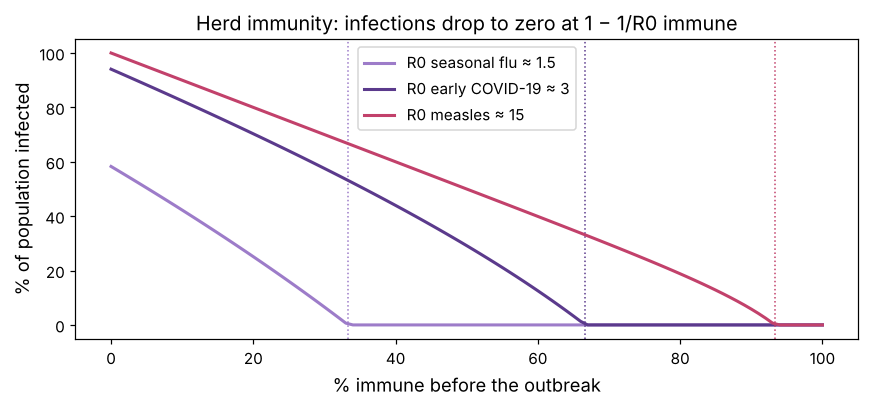

R0 = 3 with no immunity: 94% infected; measles threshold 93%


In [5]:
from scipy.optimize import brentq
def final_size(R0, v=0.0):
    Re = R0 * (1 - v)
    if Re <= 1:
        return 0.0
    return (1 - v) * brentq(lambda z: z - (1 - np.exp(-Re * z)), 1e-9, 1)

cover = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(8, 3.8))
for R0, c, name in [(1.5, "#9d7cc9", "seasonal flu ≈ 1.5"), (3, "#5b3a8c", "early COVID-19 ≈ 3"), (15, "#c2416b", "measles ≈ 15")]:
    ax.plot(100 * cover, [100 * final_size(R0, v) for v in cover], color=c, lw=2, label=f"R0 {name}")
    ax.axvline(100 * (1 - 1 / R0), color=c, ls=":", lw=1)
ax.set_xlabel("% immune before the outbreak"); ax.set_ylabel("% of population infected"); ax.legend()
ax.set_title("Herd immunity: infections drop to zero at 1 − 1/R0 immune")
save_fig("herd"); plt.show()
R["fs3"] = f"{100 * final_size(3):.0f}"; R["measles"] = f"{100 * (1 - 1 / 15):.0f}"
print(f"R0 = 3 with no immunity: {100 * final_size(3):.0f}% infected; measles threshold {100 * (1 - 1 / 15):.0f}%")

![Figure P10-3. Final epidemic size against the fraction immune before the outbreak, from the SIR final-size equation. Dotted lines mark each herd immunity threshold, 1 − 1/R0.](images/herd.png)

With $R_0 = 3$ and no immunity, about 94% of people are eventually infected; measles, with $R_0 \approx 15$, needs about 93% immunity to stop spreading. Try the second tab of the playground to see the epidemic curve itself. Epidemic modelling of this kind (with many more compartments, age structure and contact networks) guided public-health decisions throughout the COVID-19 pandemic.

:::bio
**Inflammation and cancer** are linked both ways. Chronic inflammation (from hepatitis infection, inflammatory bowel disease, *H. pylori* in the stomach) raises cancer risk through constant tissue damage and repair. And tumours recruit immune cells, such as tumour-associated macrophages, that help them grow and suppress T cells. Single-cell RNA-seq of tumours (chapter 7) maps these immune populations in detail.
:::

## Summary

| Idea | One line |
|---|---|
| Innate vs adaptive | fast generic patrol vs slow, specific, learning response |
| Antibodies | Y-shaped proteins with variable tips; neutralise and tag targets |
| V(D)J recombination | cut-and-paste of gene segments gives 10¹³ or more possible receptors |
| Clonal selection | rare matching cells expand; memory makes the next response fast |
| Affinity maturation | hypermutation plus selection improves antibodies within weeks |
| MHC/HLA | cells display peptides; killer T cells check them |
| Neoantigens | mutant peptides that let T cells recognise tumours |
| Checkpoints | PD-1/CTLA-4 brakes; blocking them is immunotherapy |
| Herd immunity | outbreaks stop once 1 − 1/R0 of people are immune |

:::check
1. Why can't antibodies alone deal with viruses hiding inside cells? *(Antibodies bind molecules outside cells; T cells see peptides from inside cells displayed on MHC.)*
2. Where does most antibody diversity come from? *(V(D)J recombination plus random additions and deletions at the joins.)*
3. Why is the second response to an infection faster? *(Memory cells are more numerous and respond to lower antigen levels.)*
4. What do PD-1 inhibitors do? *(Block a brake on T cells, letting them attack tumour cells that display PD-L1.)*
5. A disease has R0 = 4. What fraction must be immune for herd immunity? *(1 − 1/4 = 75%.)*
:::

:::exercise
Some mutations change an anchor position, making a peptide presentable *only* in the tumour. (a) For each of the common KRAS codon-12 mutations G12V, G12D and G12C, score every 9-mer and 10-mer covering the mutation, in mutant and normal form. (b) Find the peptide whose score is raised most by the mutation. Which mutation creates new anchor residues, and which don't?
:::

<details><summary>Solution</summary>

In [6]:
for aa in ["V", "D", "C"]:
    mut = kras[: pos - 1] + aa + kras[pos:]
    cands = [(a2_score(mut[s:s + L]) - a2_score(kras[s:s + L]), mut[s:s + L], a2_score(mut[s:s + L]), a2_score(kras[s:s + L]))
             for L in (9, 10) for s in range(max(0, pos - L), pos)]
    gain, pep, ms, ws = max(cands)
    print(f"G12{aa}: biggest gain {gain:+.1f} for {pep:11s} (mutant {ms:+.1f}, normal {ws:+.1f})")

G12V: biggest gain +4.0 for YKLVVVGAV   (mutant +2.0, normal -2.0)
G12D: biggest gain +0.0 for YKLVVVGAD   (mutant -2.0, normal -2.0)
G12C: biggest gain +0.0 for YKLVVVGACG  (mutant -2.0, normal -2.0)


G12V gains the most: valine is a good C-terminal anchor and an acceptable position-2 residue, so windows that put residue 12 at an anchor become presentable only in the tumour (for example the 9-mer ending at residue 12). Aspartate (G12D) is charged and cysteine (G12C) is not a preferred anchor for this HLA type, so they create no new HLA-A\*02:01 anchors. Whether a mutation yields a usable neoantigen depends on the patient's HLA genotype: G12D peptides, for example, are presented by other HLA types such as HLA-C\*08:02, and T cells against that combination have produced tumour responses in patients.

</details>